In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("Titanic-Dataset.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
df =df.drop(["PassengerId", "Name", "Cabin","Ticket"], axis=1)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [5]:
print(df["Sex"].value_counts())


Sex
male      577
female    314
Name: count, dtype: int64


In [6]:
df1=df.copy()
print(df1)
X=df1.drop(["Survived"],axis=1)
Y=df1["Survived"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, random_state=42)
X.shape

     Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0           0       3    male  22.0      1      0   7.2500        S
1           1       1  female  38.0      1      0  71.2833        C
2           1       3  female  26.0      0      0   7.9250        S
3           1       1  female  35.0      1      0  53.1000        S
4           0       3    male  35.0      0      0   8.0500        S
..        ...     ...     ...   ...    ...    ...      ...      ...
886         0       2    male  27.0      0      0  13.0000        S
887         1       1  female  19.0      0      0  30.0000        S
888         0       3  female   NaN      1      2  23.4500        S
889         1       1    male  26.0      0      0  30.0000        C
890         0       3    male  32.0      0      0   7.7500        Q

[891 rows x 8 columns]


(891, 7)

In [7]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)
X_train["Sex"] = X_train["Sex"].map({
    "male": 0,
    "female": 1
})

X_test["Sex"] = X_test["Sex"].map({
    "male": 0,
    "female": 1
})

In [8]:
from sklearn.preprocessing import LabelEncoder


X_train = pd.get_dummies(
    X_train, columns=["Embarked"], dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=["Embarked"], dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [9]:

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [10]:
print(X_train_scaled.shape)
print(Y_train.shape)
print(Y_train.isna().sum())
print(X_train.isna().sum())

(596, 9)
(596,)
0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64


In [11]:
n_neighbors = np.array([3, 5, 7, 9, 11])

# Store accuracy results
train_accuracy = []
test_accuracy = []

# Try different K values
for k in n_neighbors:

    knn = KNeighborsClassifier(n_neighbors=k)

    # Train the model
    knn.fit(X_train_scaled,Y_train )

    # Predictions
    train_pred = knn.predict(X_train_scaled)
    test_pred = knn.predict(X_test_scaled)

    # Calculate accuracy
    train_acc = accuracy_score(Y_train, train_pred)
    test_acc = accuracy_score(Y_test, test_pred)

    # Store results
    train_accuracy.append(train_acc)
    test_accuracy.append(test_acc)
    print(k,train_acc)
    print("**test",test_acc)

3 0.8590604026845637
**test 0.7898305084745763
5 0.8489932885906041
**test 0.8033898305084746
7 0.8389261744966443
**test 0.7898305084745763
9 0.8355704697986577
**test 0.8067796610169492
11 0.837248322147651
**test 0.8067796610169492


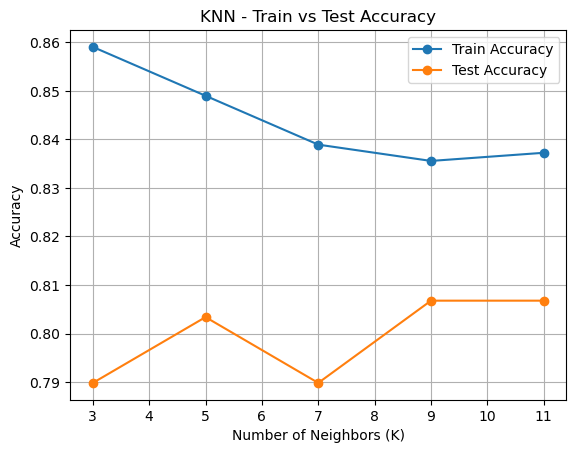

In [12]:
plt.plot(n_neighbors, train_accuracy, marker='o', label='Train Accuracy')
plt.plot(n_neighbors, test_accuracy, marker='o', label='Test Accuracy')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN - Train vs Test Accuracy')
plt.legend()
plt.grid()
plt.show()

In [17]:
knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(X_train_scaled,Y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",9
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [18]:
new_passenger =pd.DataFrame([{
    'Pclass': 1,
    'Sex': 'female',
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 80,
    'Embarked': 'S'
}])
new_passenger["Sex"] = new_passenger["Sex"].map({
    "male": 0,
    "female": 1
})

new_passenger = pd.get_dummies(
    new_passenger,
    columns=["Embarked"],
    dtype=int
)

new_passenger = new_passenger.reindex(
    columns=X_train.columns,
    fill_value=0
)

new_passenger_scaled = scaler.transform(new_passenger)

prediction = knn.predict(new_passenger_scaled)

print("Prediction:", prediction[0])
print("Probability:", knn.predict_proba(new_passenger_scaled))

Prediction: 1
Probability: [[0. 1.]]


In [19]:
new_passenger_scaled = scaler.transform(new_passenger)

prediction = knn.predict(new_passenger_scaled)

print("Prediction:", prediction[0])

Prediction: 1


In [16]:
knn.predict_proba(new_passenger_scaled)

array([[0., 1.]])